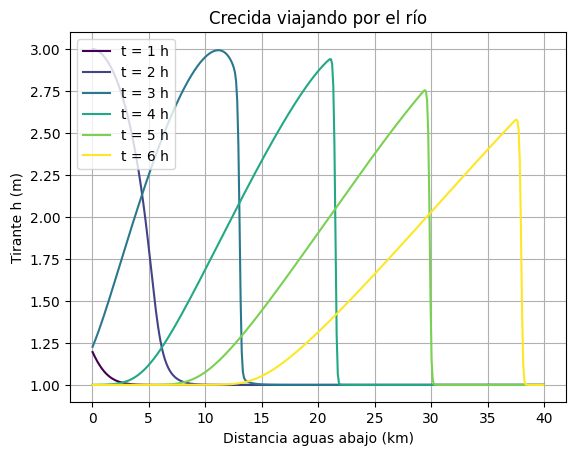

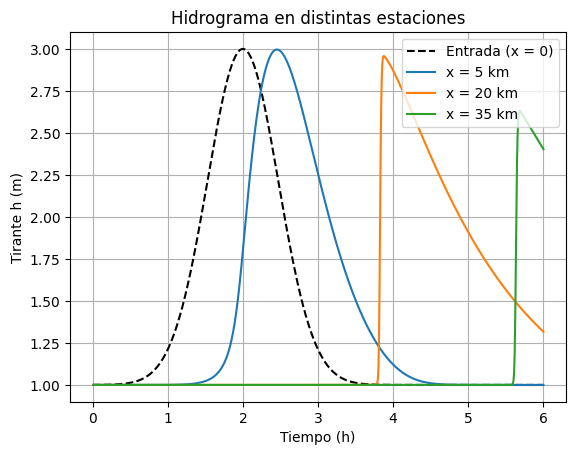

Llegada del pico a x = 5 km:
  simulada: 2.45 h
  teórica:  2.44 h


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Datos del río (cauce ancho y rectangular) ----------
n_man = 0.035                      # rugosidad de Manning
S0 = 0.001                         # pendiente del fondo
alpha = np.sqrt(S0) / n_man

def q_cin(h):                      # caudal por metro de ancho
    return alpha * h**(5/3)

def c_cin(h):                      # velocidad de la onda
    return (5/3) * alpha * h**(2/3)

# ---------- Hidrograma de entrada: tirante en el extremo de aguas arriba ----------
h_base, h_pico = 1.0, 3.0
t_pico, ancho_t = 2 * 3600, 2400   # el pico llega a las 2 h, ancho de la campana en segundos

def h_entrada(t):
    return h_base + (h_pico - h_base) * np.exp(-((t - t_pico) / ancho_t)**2)

# ---------- Flujo ----------
def flujo_rusanov(f, df, ul, ur):
    a = np.maximum(np.abs(df(ul)), np.abs(df(ur)))
    return 0.5 * (f(ul) + f(ur)) - 0.5 * a * (ur - ul)

# ---------- Simulación ----------
def simular_crecida(N=400, L=40_000, t_final=6 * 3600, cfl=0.8,
                    estaciones=(5_000, 20_000, 35_000)):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    h = np.full(N, h_base)                         # el río empieza con tirante uniforme
    idx = [int(xe / dx) for xe in estaciones]      # casilla de cada estación de medición
    t, proxima = 0.0, 3600.0
    fotos, t_reg, h_reg = {}, [], []

    while t < t_final - 1e-9:
        h_ent = h_entrada(t)
        c_max = max(np.max(c_cin(h)), c_cin(h_ent))
        dt = min(cfl * dx / c_max, proxima - t)
        up = np.concatenate(([h_ent], h, [h[-1]]))         # entra el hidrograma, sale libre
        F = flujo_rusanov(q_cin, c_cin, up[:-1], up[1:])
        h = h - dt / dx * (F[1:] - F[:-1])
        t += dt
        t_reg.append(t)
        h_reg.append([h[i] for i in idx])                  # anota el tirante en cada estación
        if abs(t - proxima) < 1e-6:
            fotos[round(proxima / 3600)] = h.copy()
            proxima += 3600.0
    return x, fotos, np.array(t_reg), np.array(h_reg), estaciones

x, fotos, t_reg, h_reg, estaciones = simular_crecida()

# ---------- Figura 1: perfil del río cada hora ----------
horas = sorted(fotos)
colores = plt.cm.viridis(np.linspace(0, 1, len(horas)))
for hr, c in zip(horas, colores):
    plt.plot(x / 1000, fotos[hr], color=c, label=f"t = {hr} h")
plt.xlabel("Distancia aguas abajo (km)"); plt.ylabel("Tirante h (m)")
plt.title("Crecida viajando por el río")
plt.legend(loc="upper left"); plt.grid(True)
plt.show()

# ---------- Figura 2: hidrogramas en tres estaciones ----------
t_h = np.linspace(0, 6 * 3600, 500)
plt.plot(t_h / 3600, h_entrada(t_h), "k--", label="Entrada (x = 0)")
for k, xe in enumerate(estaciones):
    plt.plot(t_reg / 3600, h_reg[:, k], label=f"x = {xe/1000:.0f} km")
plt.xlabel("Tiempo (h)"); plt.ylabel("Tirante h (m)")
plt.title("Hidrograma en distintas estaciones")
plt.legend(loc="upper right"); plt.grid(True)
plt.show()

# ---------- ¿cuándo llega el pico a la primera estación? ----------
t_sim = t_reg[np.argmax(h_reg[:, 0])]
t_teo = t_pico + estaciones[0] / c_cin(h_pico)
print(f"Llegada del pico a x = {estaciones[0]/1000:.0f} km:")
print(f"  simulada: {t_sim/3600:.2f} h")
print(f"  teórica:  {t_teo/3600:.2f} h")

In [2]:
def datos_choque(h):
    i = np.argmin(np.diff(h))            # casilla donde el tirante cae más bruscamente
    return x[i], h[i - 2]                # posición del choque y tirante justo detrás

for h1, h2 in [(4, 5), (5, 6)]:
    x1, hL1 = datos_choque(fotos[h1])
    x2, hL2 = datos_choque(fotos[h2])
    v_sim = (x2 - x1) / 3600
    hL = 0.5 * (hL1 + hL2)
    v_teo = (q_cin(hL) - q_cin(h_base)) / (hL - h_base)
    print(f"De {h1} h a {h2} h: velocidad simulada = {v_sim:.2f} m/s, teórica = {v_teo:.2f} m/s")

De 4 h a 5 h: velocidad simulada = 2.33 m/s, teórica = 2.29 m/s
De 5 h a 6 h: velocidad simulada = 2.25 m/s, teórica = 2.21 m/s
